# Pair 1: Fake review detection

**COMP8410 Assignment 1. Name: Arnob Deb Student ID: 60841338.**

A large online travel platform needs to find fake reviews. This notebook compares two graph
neural networks on the public YelpChi dataset, and holds all the code for this pair.

Models used in this notebook: 1. FAGCN (Bo et al., 2021) 2. BWGNN (Tang et al., 2022)
Baselines: MLP, GCN, H2GCN and XGB-Graph


How to use it: Keep this notebook in the same folder as the results and data folders,
open it and run every cell from top to bottom. RUN_TRAINING is False, so the notebook loads
the trained models and results saved in results. It needs no GPU and takes a few minutes. Set it
to True to train every model again which takes about an hour on an RTX 4060 Ti and replaces
the files in results. The README explains the setup.

Where the results came from: The final training run was done from an earlier copy of this folder (60841338_Evaluation\pair1_fake_reviews) as the last line of the log shows, and its results folder was copied here unchanged.

In [1]:
import hashlib, json, platform, random, time, urllib.request, zipfile
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display
from scipy.special import beta as beta_function
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

RUN_TRAINING = False   
QUICK = False         

SEEDS, EPOCHS, PATIENCE, TREES = 3, 2000, 100, 2000
HIDDEN, LR, DROPOUT = 32, 0.005, 0.3  # Hidden size 32 keeps FAGCN within an 8 GB GPU.
if QUICK:
    SEEDS, EPOCHS, PATIENCE, TREES, HIDDEN = 1, 3, 3, 50, 16

try:
    HERE = Path(__vsc_ipynb_file__).parent
except NameError:
    HERE = Path.cwd()
RESULTS = HERE / ("results_quick" if QUICK else "results")
print(f"Using the files in {HERE}")
if not RUN_TRAINING and not (RESULTS / "runs.csv").exists():
    raise FileNotFoundError(f"No saved results in {RESULTS}. Keep the notebook next to its results folder.")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Using the files in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair1_fake_reviews


## 1. Data

YelpChi holds about 46,000 hotel and restaurant reviews with 32 numeric features each. It links
between related reviews and a label saying whether each review is fake. 

Builds the "camouflage" test graph where fake reviews gain extra links to genuine reviews.

Camouflage imitates fraudsters hiding among normal users which Week 11 describes as
heterophily. It also creates a distribution shift which Week 12 describes as a non-IID setting.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/YingtongDou/CARE-GNN/master/data/YelpChi.zip"
DATA_SHA256 = "3a31296b951e6c8158dddb783ff2c62709fa987d106bbe21e59f8e119053cec3"


def clean_graph(matrix):
    matrix = sp.csr_matrix(matrix, dtype=np.float32)
    matrix = matrix.maximum(matrix.T)
    matrix.setdiag(0)
    matrix.eliminate_zeros()
    matrix.data[:] = 1.0
    return matrix.tocsr()


def load_yelpchi(folder):
    folder.mkdir(exist_ok=True)
    mat_path, zip_path = folder / "YelpChi.mat", folder / "YelpChi.zip"
    if not mat_path.exists():
        if not zip_path.exists():
            urllib.request.urlretrieve(DATA_URL, zip_path)
        if hashlib.sha256(zip_path.read_bytes()).hexdigest() != DATA_SHA256:
            raise RuntimeError("YelpChi.zip is not the expected file. Delete it and run again.")
        zipfile.ZipFile(zip_path).extractall(folder)
    mat = sio.loadmat(mat_path)
    features = np.asarray(mat["features"].todense(), dtype=np.float32)
    std = features.std(axis=0, keepdims=True)
    std[std == 0] = 1.0
    data = {
    
        "x": (features - features.mean(axis=0, keepdims=True)) / std,
        "y": np.asarray(mat["label"]).ravel().astype(np.int64),  # 1 = fake, 0 = genuine.
        "graph": clean_graph(mat["homo"]),                     
        
        "user_reviews": np.asarray(clean_graph(mat["net_rur"]).sum(axis=1)).ravel().astype(np.int64) + 1,
    }
    return data


def make_split(y, seed):
    train, rest = train_test_split(np.arange(len(y)), train_size=0.4, stratify=y, random_state=seed)
    val, test = train_test_split(rest, train_size=1 / 3, stratify=y[rest], random_state=seed)
    return {"train": train, "val": val, "test": test}


def camouflage(graph, y, test, links, seed):
    if links == 0:
        return graph
    rng = np.random.default_rng(seed)
    sources = np.repeat(test[y[test] == 1], links)
    targets = rng.choice(np.flatnonzero(y == 0), size=len(sources), replace=True)
    extra = sp.csr_matrix((np.ones(len(sources), dtype=np.float32), (sources, targets)), shape=graph.shape)
    return clean_graph(graph + extra)


class Graph:
    def __init__(self, adjacency):
        coo = adjacency.tocoo()
        self.src = torch.as_tensor(coo.row, dtype=torch.long, device=DEVICE)
        self.dst = torch.as_tensor(coo.col, dtype=torch.long, device=DEVICE)
        degree = torch.as_tensor(np.asarray(adjacency.sum(axis=1)).ravel().astype(np.float32), device=DEVICE).clamp(min=1.0)
        self.norm = 1.0 / torch.sqrt(degree[self.src] * degree[self.dst])
       
        self.back = torch.zeros(adjacency.shape[0], device=DEVICE).index_add(0, self.src, self.norm**2)
        self.adj = torch.sparse_coo_tensor(torch.stack([self.src, self.dst]), self.norm, size=adjacency.shape,
                                           device=DEVICE, check_invariants=False).coalesce()

## 2. Scoring

Only 1 in 7 reviews is fake, so accuracy would mislead. The scores are AUROC, AUPRC, Rec@K and
F1-macro, plus two moderation-team measures and a fairness check by reviewer activity.

In [3]:
def best_threshold(y, scores):

    options = np.unique(np.quantile(scores, np.linspace(0.01, 0.99, 99)))
    return float(options[np.argmax([f1_score(y, scores >= t, average="macro", zero_division=0) for t in options])])


def scores_for(y, scores, threshold):

    k = int(y.sum())  
    flagged = scores >= threshold
    return {
        "auroc": roc_auc_score(y, scores),
        "auprc": average_precision_score(y, scores),
        "rec_at_k": float(y[np.argsort(-scores)[:k]].sum() / k),
        "f1_macro": f1_score(y, flagged, average="macro", zero_division=0),
        "caught_per_1000": float(y[np.argsort(-scores)[:1000]].mean() * 1000),       
        "false_alarms_per_1000_genuine": float(flagged[y == 0].mean() * 1000),        
    }


def activity_group(counts):
    groups = np.full(len(counts), "6 or more reviews", dtype=object)
    groups[counts <= 5] = "2 to 5 reviews"
    groups[counts == 1] = "1 review"
    return groups


def fairness(y, scores, threshold, groups):
    rows, flagged = [], scores >= threshold
    for group in sorted(set(groups)):
        mask = groups == group
        rows.append({"group": group, "reviews": int(mask.sum()), "fake_reviews": int((mask & (y == 1)).sum()),
                     "fake_share": float(y[mask].mean()), "recall": float(flagged[mask & (y == 1)].mean()),
                     "false_positive_rate": float(flagged[mask & (y == 0)].mean())})
    return rows

## 3. Models

Every neural model gets the same features and links and returns a "genuine" and a "fake" score.
MLP ignores the links. GCN averages neighbours (low-pass). H2GCN keeps a review apart from its
neighbours and also looks two steps away. FAGCN learns to add or subtract each neighbour. BWGNN
keeps low, middle and high graph frequencies side by side, because anomalies shift to high frequencies.

In [4]:
class MLP(nn.Module):
    def __init__(self, d, h, p):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, 2))
    def forward(self, x, g):
        return self.net(x)


class GCN(nn.Module):
    def __init__(self, d, h, p):
        super().__init__()
        self.layer1, self.layer2, self.p = nn.Linear(d, h), nn.Linear(h, 2), p
    def forward(self, x, g):
        h = F.dropout(F.relu(self.layer1(x + torch.sparse.mm(g.adj, x))), self.p, self.training)
        return self.layer2(h + torch.sparse.mm(g.adj, h))


class H2GCN(nn.Module):
    def __init__(self, d, h, p, rounds=2):
        super().__init__()
        self.embed, self.p, self.rounds = nn.Linear(d, h), p, rounds
        self.classify = nn.Linear(h * (2 ** (rounds + 1) - 1), 2)  
    def forward(self, x, g):
        h = F.dropout(F.relu(self.embed(x)), self.p, self.training)
        kept = [h]
        for _ in range(self.rounds):
            one = torch.sparse.mm(g.adj, h)
            two = torch.sparse.mm(g.adj, one) - g.back.unsqueeze(1) * h  
            h = torch.cat([one, two], dim=1)
            kept.append(h)
        return self.classify(F.dropout(torch.cat(kept, dim=1), self.p, self.training))


class FAGCNLayer(nn.Module):

    def __init__(self, h, eps, p):
        super().__init__()
        self.g_left, self.g_right = nn.Linear(h, 1, bias=False), nn.Linear(h, 1, bias=False)
        self.eps, self.p = eps, p
    def forward(self, h, h0, g):
        alpha = torch.tanh(self.g_left(h).squeeze(-1)[g.dst] + self.g_right(h).squeeze(-1)[g.src])
        alpha = F.dropout(alpha, self.p, self.training)
        messages = (alpha * g.norm).unsqueeze(-1) * h[g.src]
        return self.eps * h0 + torch.zeros_like(h).index_add(0, g.dst, messages)


class FAGCN(nn.Module):
    """Platform A."""
    def __init__(self, d, h, p, eps=0.3, layers=2):
        super().__init__()
        self.embed = nn.Linear(d, h)
        self.layers = nn.ModuleList([FAGCNLayer(h, eps, p) for _ in range(layers)])
        self.classify, self.p = nn.Linear(h, 2), p
    def forward(self, x, g):
        h0 = h = F.dropout(F.relu(self.embed(x)), self.p, self.training)
        for layer in self.layers:
            h = layer(h, h0, g)
        return self.classify(h)


class BWGNN(nn.Module):
    def __init__(self, d, h, p, order=2):
        super().__init__()
        self.embed = nn.Linear(d, h)
        theta = np.zeros((order + 1, order + 1))
        for i in range(order + 1):
            for k in range(order - i + 1):
                theta[i, i + k] = comb(order - i, k) * (-1) ** k * 0.5 ** (i + k) / beta_function(i + 1, order - i + 1)
        self.register_buffer("theta", torch.tensor(theta, dtype=torch.float32))
        self.head = nn.Sequential(nn.Linear(h * (order + 1), h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, 2))
        self.p, self.order = p, order
    def forward(self, x, g):
        powers = [F.dropout(F.relu(self.embed(x)), self.p, self.training)]
        for _ in range(self.order):
            powers.append(powers[-1] - torch.sparse.mm(g.adj, powers[-1])) 
        bands = torch.einsum("fp,prh->frh", self.theta, torch.stack(powers))
        return self.head(bands.permute(1, 0, 2).reshape(x.shape[0], -1))  


MODELS = {"MLP": MLP, "GCN": GCN, "FAGCN": FAGCN, "H2GCN": H2GCN, "BWGNN": BWGNN}

## 4. Training and testing

For each seed, I train with the training split and use validation AUPRC for early stopping. I also choose the classification threshold from validation data, not the test labels. XGB-Graph uses its own training routine because it isn't trained with the neural-network optimiser.

In [5]:

@torch.no_grad()
def fake_scores(model, x, g):
    model.eval()
    return F.softmax(model(x, g), dim=1)[:, 1].cpu().numpy()


def train_gnn(name, data, x, labels, g, split):
    model = MODELS[name](x.shape[1], HIDDEN, DROPOUT).to(DEVICE)
    optimiser = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=5e-5)
    train = torch.as_tensor(split["train"], device=DEVICE)
    share = float(labels[train].float().mean())
    weight = torch.tensor([1.0, (1 - share) / share], device=DEVICE)  
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    best, best_state, best_epoch, waited, history, started = -1.0, None, 0, 0, [], time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        optimiser.zero_grad()
        loss = F.cross_entropy(model(x, g)[train], labels[train], weight=weight)
        loss.backward()
        optimiser.step()
        val = average_precision_score(data["y"][split["val"]], fake_scores(model, x, g)[split["val"]])
        history.append({"epoch": epoch, "val_auprc": val})
        if val > best:
            best, best_epoch, waited = val, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
        if epoch == 1 or epoch % 50 == 0:
            print(f"    epoch {epoch:4d}  loss {loss.item():.4f}  val AUPRC {val:.4f}")
        if waited >= PATIENCE:
            print(f"    stopped early at epoch {epoch}")
            break
    model.load_state_dict(best_state)
    info = {"train_seconds": time.perf_counter() - started, "epochs_run": epoch, "best_epoch": best_epoch,
            "peak_gpu_gb": torch.cuda.max_memory_allocated() / 1024**3 if DEVICE.type == "cuda" else np.nan,
            "parameters": sum(p.numel() for p in model.parameters())}
    return model, info, history


def neighbour_features(x, graph):
    mean = sp.diags(1.0 / np.maximum(np.asarray(graph.sum(axis=1)).ravel(), 1.0)) @ graph
    one = mean @ x
    return np.hstack([x, one, mean @ one]).astype(np.float32)


def train_xgb(inputs, y, split, seed):
    share = y[split["train"]].mean()
    model = XGBClassifier(n_estimators=TREES, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                          scale_pos_weight=(1 - share) / share, tree_method="hist", device=DEVICE.type,
                          early_stopping_rounds=50, eval_metric="aucpr", random_state=seed)
    started = time.perf_counter()
    model.fit(inputs[split["train"]], y[split["train"]], eval_set=[(inputs[split["val"]], y[split["val"]])], verbose=False)
    info = {"train_seconds": time.perf_counter() - started, "epochs_run": model.get_booster().num_boosted_rounds(),
            "best_epoch": model.best_iteration + 1, "peak_gpu_gb": np.nan, "parameters": np.nan}
    return model, info

In [6]:
def run_everything():
    (RESULTS / "models").mkdir(parents=True, exist_ok=True)
    data = load_yelpchi(HERE / "data")
    y, groups = data["y"], activity_group(data["user_reviews"])
    x, labels, g = torch.as_tensor(data["x"], device=DEVICE), torch.as_tensor(y, device=DEVICE), Graph(data["graph"])
    out = {name: [] for name in ["runs", "fairness", "camouflage", "failure_cases", "training_curves"]}
    print(f"Running on {torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'}")

    for seed in range(SEEDS):
        split = make_split(y, seed)
        test = split["test"]
        xgb_inputs = neighbour_features(data["x"], data["graph"])
        for name in list(MODELS) + ["XGB-Graph"]:
            print(f"\nSeed {seed}: {name}")
            random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
            if name == "XGB-Graph":
                model, info = train_xgb(xgb_inputs, y, split, seed)
                predict = lambda graph: model.predict_proba(xgb_inputs if graph is None else neighbour_features(data["x"], graph))[:, 1]
                if seed == 0:
                    model.save_model(RESULTS / "models" / "XGB-Graph.json")
            else:
                model, info, history = train_gnn(name, data, x, labels, g, split)
                predict = lambda graph: fake_scores(model, x, g if graph is None else Graph(graph))
                out["training_curves"] += [{"model": name, "seed": seed, **row} for row in history]
                if seed == 0:
                    torch.save(model.state_dict(), RESULTS / "models" / f"{name}.pt")

            scores = predict(None)
            threshold = best_threshold(y[split["val"]], scores[split["val"]])
            started = time.perf_counter()
            predict(None)
            info["inference_ms_per_1000"] = (time.perf_counter() - started) * 1000 / (len(y) / 1000)
            out["runs"].append({"model": name, "seed": seed, "threshold": threshold, **scores_for(y[test], scores[test], threshold), **info})
            out["fairness"] += [{"model": name, "seed": seed, **row} for row in fairness(y[test], scores[test], threshold, groups[test])]

            if seed == 0: 
                ranked = test[np.argsort(-scores[test])]
                for kind, ids in [("false alarm", ranked[y[ranked] == 0][:20]), ("missed fake", ranked[y[ranked] == 1][-20:])]:
                    out["failure_cases"] += [{"model": name, "type": kind, "review_id": int(i), "score": float(scores[i]),
                                              "reviewer_reviews": int(data["user_reviews"][i])} for i in ids]

            for links in [0, 25, 100, 400]:  
                changed = predict(None if links == 0 else camouflage(data["graph"], y, test, links, seed))
                out["camouflage"].append({"model": name, "seed": seed, "links_per_fake": links, **scores_for(y[test], changed[test], threshold)})

            for file, rows in out.items():
                pd.DataFrame(rows).to_csv(RESULTS / f"{file}.csv", index=False)

    summary = pd.DataFrame(out["runs"]).drop(columns="seed").groupby("model", sort=False).agg(["mean", "std"]).round(4)
    summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
    summary.to_csv(RESULTS / "summary.csv")
    settings = {"seeds": SEEDS, "epochs": EPOCHS, "patience": PATIENCE, "trees": TREES, "hidden": HIDDEN,
                "lr": LR, "dropout": DROPOUT, "quick": QUICK}
    (RESULTS / "environment.json").write_text(json.dumps(
        {"python": platform.python_version(), "torch": torch.__version__,
         "device": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU", "settings": settings,
         "fake_share": float(y.mean()), "reviews": int(len(y)), "links": int(data["graph"].nnz / 2)}, indent=2))
    print(f"\nFinished. Results are in {RESULTS}")

## 5. Run the evaluation

With `RUN_TRAINING = False`, this cell does nothing and the saved results are used.

In [7]:
if RUN_TRAINING:
    run_everything()
else:
    print(f"Skipping training. Using the saved results in {RESULTS}")

Skipping training. Using the saved results in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair1_fake_reviews\results


## 6. Results

Means across the three seeds. epochs_run shows that early stopping, not the limit, ended training.

In [8]:
print(json.dumps(json.loads((RESULTS / "environment.json").read_text()), indent=2))
runs = pd.read_csv(RESULTS / "runs.csv")
display(runs.groupby("model", sort=False)[["auroc", "auprc", "rec_at_k", "f1_macro", "caught_per_1000",
        "false_alarms_per_1000_genuine", "train_seconds", "epochs_run", "peak_gpu_gb", "inference_ms_per_1000"]].mean().round(3))
display(runs.groupby("model", sort=False)["auprc"].std().round(3).to_frame("auprc_std"))  # Spread across seeds.

fair = pd.read_csv(RESULTS / "fairness.csv")
display(fair.groupby(["model", "group"], sort=False)[["fake_reviews", "recall", "false_positive_rate"]].mean().round(3))

camo = pd.read_csv(RESULTS / "camouflage.csv")
display(camo.groupby(["model", "links_per_fake"], sort=False)["auprc"].mean().unstack().round(3))
display(camo[camo["links_per_fake"] == 400].pivot(index="model", columns="seed", values="auroc").round(3))  

# Gaps: reviews in every model's worst-mistakes list.
fails = pd.read_csv(RESULTS / "failure_cases.csv")
shared = fails.groupby(["review_id", "type"])["model"].nunique().reset_index()
display(shared[shared["model"] == fails["model"].nunique()])

{
  "python": "3.11.9",
  "torch": "2.14.1+cu126",
  "device": "NVIDIA GeForce RTX 4060 Ti",
  "settings": {
    "seeds": 3,
    "epochs": 2000,
    "patience": 100,
    "trees": 2000,
    "hidden": 32,
    "lr": 0.005,
    "dropout": 0.3,
    "quick": false
  },
  "fake_share": 0.14529747138442792,
  "reviews": 45954,
  "links": 3846979
}


,auroc,auprc,rec_at_k,f1_macro,caught_per_1000,false_alarms_per_1000_genuine,train_seconds,epochs_run,peak_gpu_gb,inference_ms_per_1000
model,,,,,,,,,,
MLP,0.856,0.573,0.546,0.733,753.000,74.109,2.006,550.667,0.342,0.014
GCN,0.865,0.591,0.553,0.739,757.000,78.968,66.732,1233.667,0.799,0.228
FAGCN,0.877,0.639,0.579,0.752,816.000,59.979,193.206,942.333,6.000,1.005
H2GCN,0.863,0.591,0.550,0.737,765.333,82.766,198.932,1287.667,0.859,0.234
BWGNN,0.891,0.678,0.615,0.772,849.333,75.425,48.232,629.667,0.816,0.110
XGB-Graph,0.963,0.874,0.787,0.876,982.667,32.652,170.402,1022.667,NaN,0.946


,auprc_std
model,
MLP,0.018
GCN,0.006
FAGCN,0.014
H2GCN,0.006
BWGNN,0.013
XGB-Graph,0.001


fake_reviews  recall  false_positive_rate
model     group                                                       
MLP       1 review                 2197.0   0.542                0.075
          2 to 5 reviews            453.0   0.505                0.074
          6 or more reviews          21.0   0.394                0.072
GCN       1 review                 2197.0   0.582                0.089
          2 to 5 reviews            453.0   0.473                0.074
          6 or more reviews          21.0   0.391                0.064
FAGCN     1 review                 2197.0   0.562                0.067
          2 to 5 reviews            453.0   0.454                0.058
          6 or more reviews          21.0   0.408                0.049
H2GCN     1 review                 2197.0   0.589                0.090
          2 to 5 reviews            453.0   0.475                0.080
          6 or more reviews          21.0   0.423                0.073
BWGNN     1 review                 2197.0   0.660                0.081
          2 to 5 reviews            453.0   0.538                0.075
          6 or more reviews          21.0   0.472                0.062
XGB-Graph 1 review                 2197.0   0.809                0.034
          2 to 5 reviews            453.0   0.616                0.035
          6 or more reviews          21.0   0.506                0.024

links_per_fake,0,25,100,400
model,,,,
MLP,0.573,0.573,0.573,0.573
GCN,0.591,0.512,0.358,0.160
FAGCN,0.639,0.575,0.442,0.359
H2GCN,0.591,0.559,0.499,0.389
BWGNN,0.678,0.576,0.370,0.178
XGB-Graph,0.874,0.823,0.759,0.646


seed,0,1,2
model,,,
BWGNN,0.558,0.665,0.543
FAGCN,0.865,0.768,0.191
GCN,0.518,0.594,0.517
H2GCN,0.719,0.777,0.754
MLP,0.849,0.853,0.865
XGB-Graph,0.884,0.878,0.875


,review_id,type,model
102,38450,missed fake,6


## 7. Charts

The charts read the saved CSV files only, so every plotted number traces to a result file.
They are saved in results/figures.

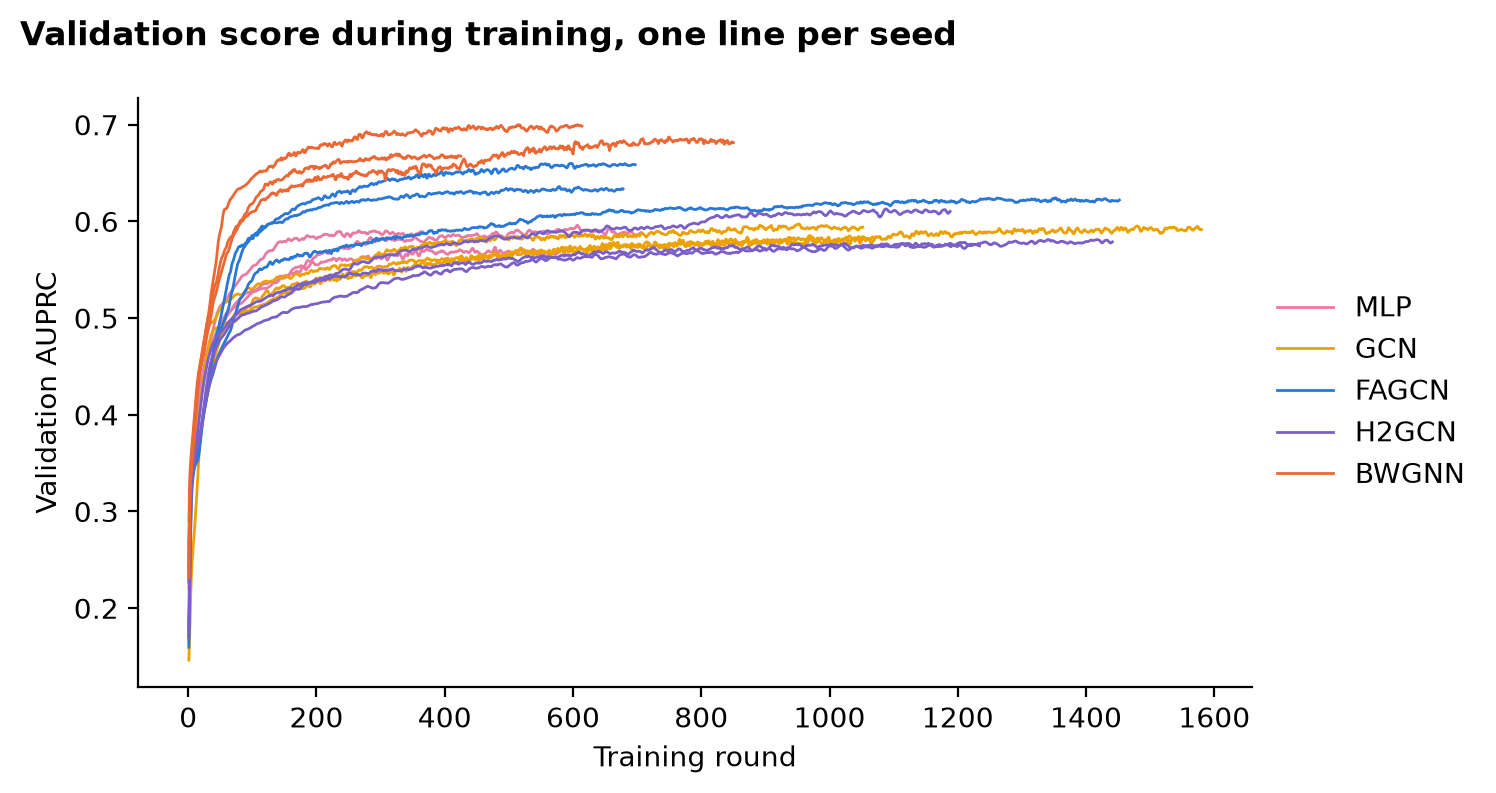

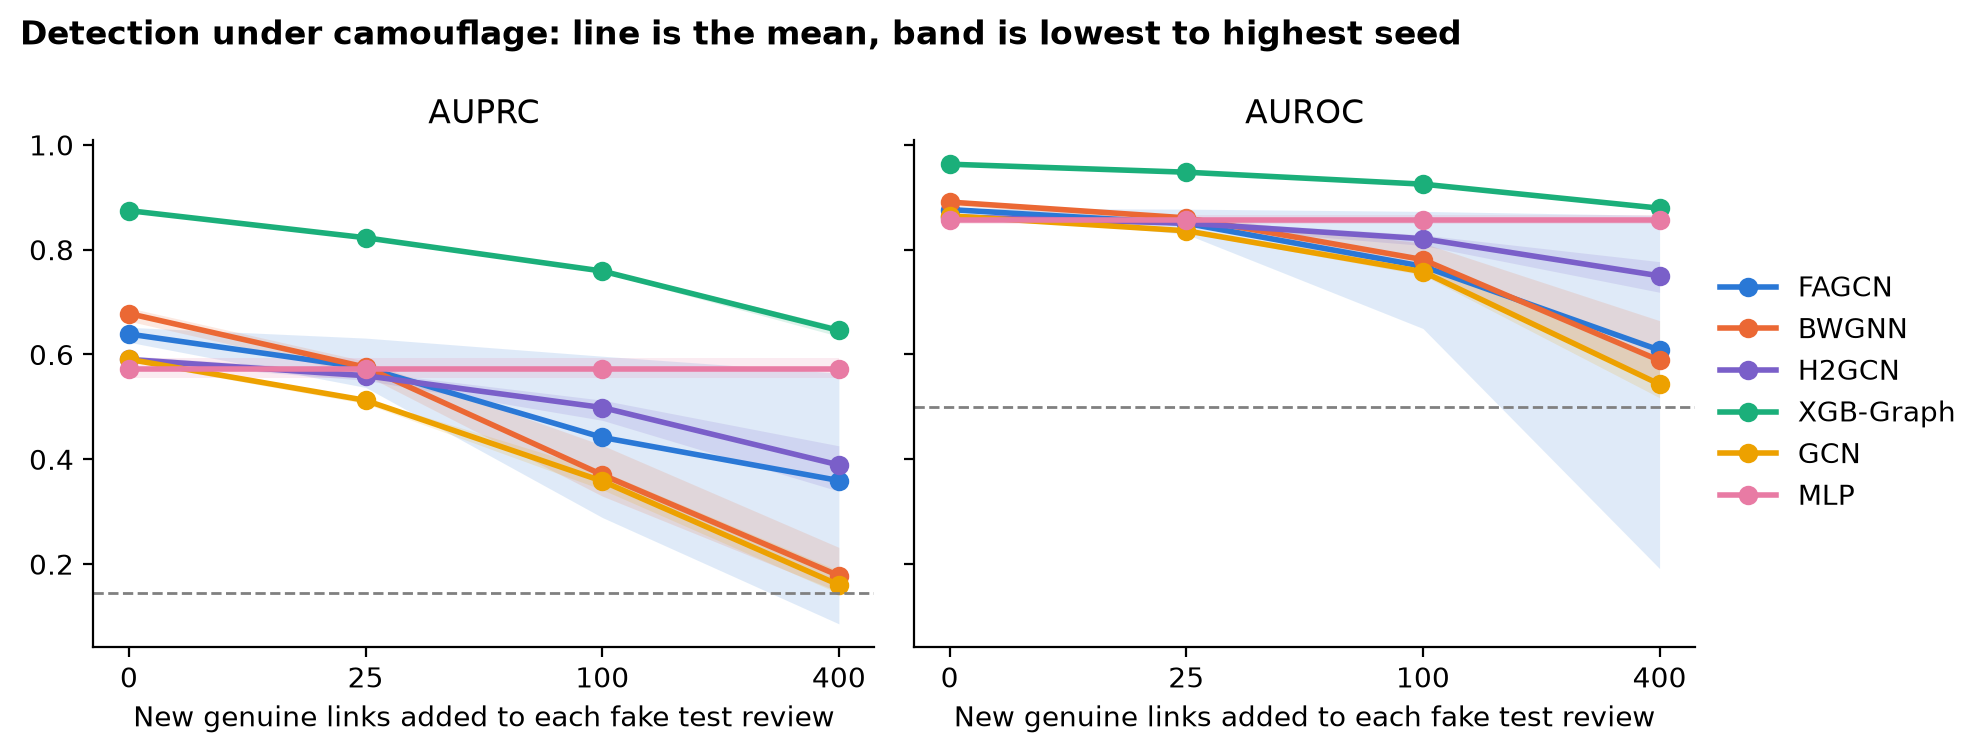

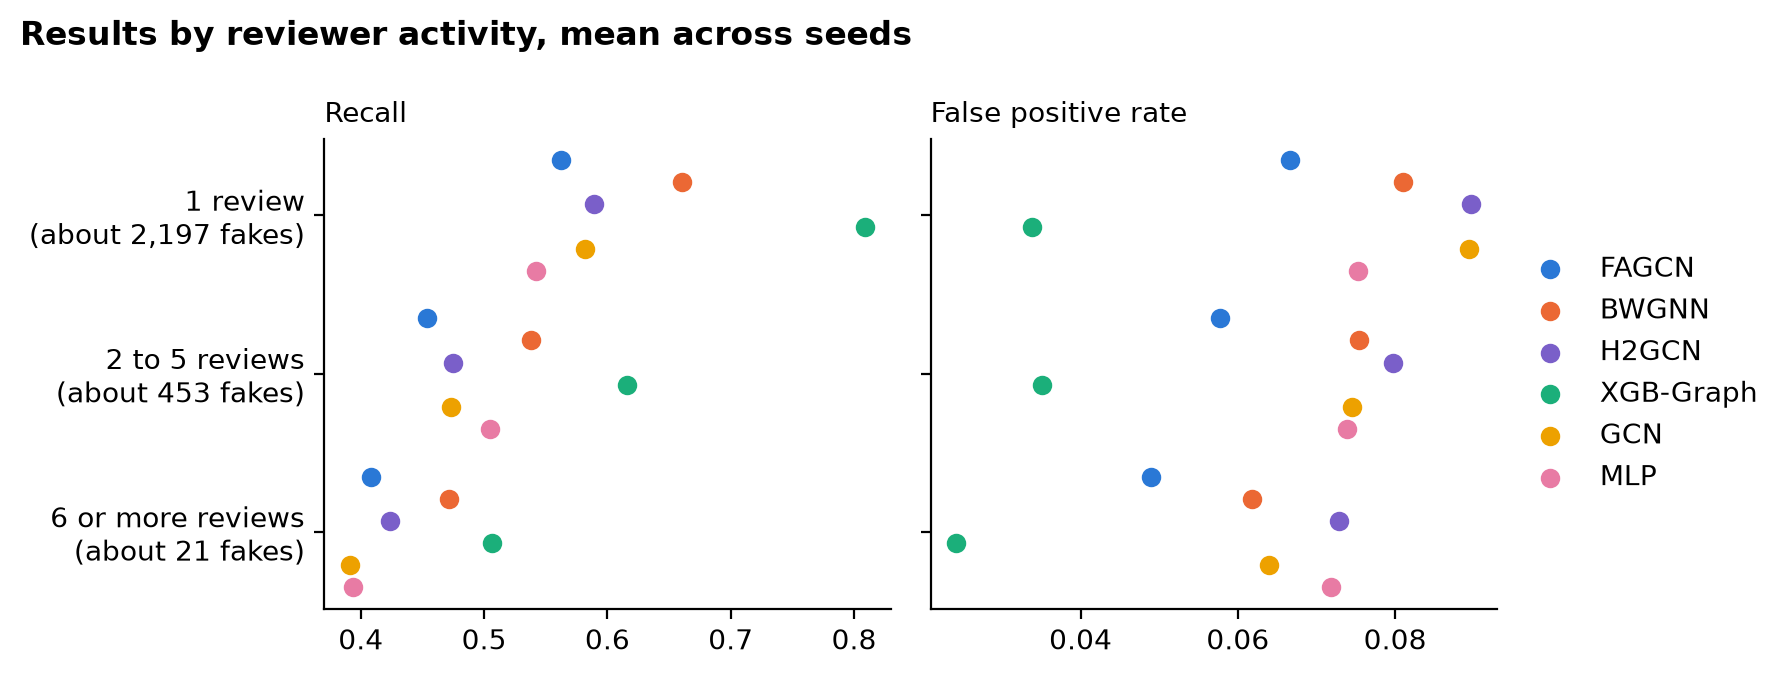

In [9]:

COLOURS = {"FAGCN": "#2a78d6", "BWGNN": "#eb6834", "H2GCN": "#7a5fc9", "XGB-Graph": "#1baf7a", "GCN": "#eda100", "MLP": "#e87ba4"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200, "savefig.bbox": "tight"})
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)


def save(fig, title, file):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    fig.savefig(FIGURES / file)
    plt.close(fig)


fig, axis = plt.subplots(figsize=(7.5, 4))
training = pd.read_csv(RESULTS / "training_curves.csv")
for model in MODELS:
    for index, (_, part) in enumerate(training[training["model"] == model].groupby("seed")):
        axis.plot(part["epoch"], part["val_auprc"], color=COLOURS[model], linewidth=1, label=model if index == 0 else None)
axis.set(xlabel="Training round", ylabel="Validation AUPRC")
axis.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
save(fig, "Validation score during training, one line per seed", "fig1_training.png")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
means = fair.groupby(["model", "group"])[["recall", "false_positive_rate"]].mean()
groups = ["1 review", "2 to 5 reviews", "6 or more reviews"]
for axis, metric in zip(axes, ["recall", "false_positive_rate"]):
    for index, model in enumerate(COLOURS):
        axis.scatter([means.loc[(model, grp), metric] for grp in groups], [r - 0.35 + 0.14 * index for r in range(3)], color=COLOURS[model], label=model)
    axis.set_title(metric.replace("_", " ").capitalize(), loc="left", fontsize=10)
fakes = fair.groupby("group")["fake_reviews"].mean()
axes[0].set_yticks(range(3), [f"{grp}\n(about {fakes[grp]:,.0f} fakes)" for grp in groups])
axes[0].invert_yaxis()
axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
save(fig, "Results by reviewer activity, mean across seeds", "fig3_fairness.png")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for axis, metric, chance in [(axes[0], "auprc", 0.145), (axes[1], "auroc", 0.5)]:
    stats = camo.groupby(["model", "links_per_fake"])[metric].agg(["mean", "min", "max"])
    for model in COLOURS:
        part = stats.loc[model]
        axis.fill_between(range(4), part["min"], part["max"], color=COLOURS[model], alpha=0.15, linewidth=0)
        axis.plot(range(4), part["mean"], color=COLOURS[model], marker="o", linewidth=2, label=model)
    axis.axhline(chance, color="grey", linestyle="--", linewidth=1)
    axis.set(xticks=range(4), xticklabels=[0, 25, 100, 400], xlabel="New genuine links added to each fake test review", title=metric.upper())
axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
save(fig, "Detection under camouflage: line is the mean, band is lowest to highest seed", "fig2_camouflage.png")

for chart in sorted(FIGURES.glob("fig*.png")):
    display(Image(filename=str(chart), width=800))

## 8. Input-to-output demo

Loads the saved first-seed models and shows four test reviews: a caught fake, a missed fake, a
disagreement between the two platforms, and a correctly allowed genuine review. They are chosen by
outcome, so they are illustrations; the tables above show how often each outcome happens.

In [10]:

DEMO_MODELS = ["FAGCN", "BWGNN", "XGB-Graph"]
data = load_yelpchi(HERE / "data")
y, x, g = data["y"], torch.as_tensor(data["x"], device=DEVICE), Graph(data["graph"])

scores = {}
for name in DEMO_MODELS:
    if name == "XGB-Graph":
        model = XGBClassifier()
        model.load_model(RESULTS / "models" / "XGB-Graph.json")
        scores[name] = model.predict_proba(neighbour_features(data["x"], data["graph"]))[:, 1]
    else:
        model = MODELS[name](x.shape[1], HIDDEN, 0.0).to(DEVICE)
        model.load_state_dict(torch.load(RESULTS / "models" / f"{name}.pt", map_location=DEVICE))
        scores[name] = fake_scores(model, x, g)
cut = runs[runs["seed"] == 0].set_index("model")["threshold"]  # First-seed cut-offs, chosen on validation data.

test = make_split(y, 0)["test"]
flag = {n: scores[n][test] >= cut[n] for n in DEMO_MODELS}
everyone, nobody = flag["FAGCN"] & flag["BWGNN"] & flag["XGB-Graph"], ~flag["FAGCN"] & ~flag["BWGNN"] & ~flag["XGB-Graph"]
cases = [("Fake review caught by all three models", (y[test] == 1) & everyone),
         ("Fake review missed by all three models", (y[test] == 1) & nobody),
         ("Fake review where FAGCN and BWGNN disagree", (y[test] == 1) & (flag["FAGCN"] != flag["BWGNN"])),
         ("Genuine review allowed by all three models", (y[test] == 0) & nobody)]
rng = np.random.default_rng(0)  # Same examples every time.
for title, match in cases:
    if not match.any():
        print(f"\nNo test review matches: {title}")
        continue
    review = int(rng.choice(test[match]))
    links = data["graph"][review].indices
    print(f"\n=== {title} ===\nINPUT: review {review}\n  Numeric features: {x.shape[1]}")
    print(f"  Linked reviews: {len(links)}, of which {int(y[links].sum())} are labelled fake\n  Reviews by this user: {data['user_reviews'][review]}\nOUTPUT:")
    for name in DEMO_MODELS:
        s = float(scores[name][review])
        print(f"  {name:<10} score {s:.3f}  cut-off {cut[name]:.3f}  {'FLAG FOR CHECKING' if s >= cut[name] else 'allow'}")
    print(f"TRUE LABEL: {'FAKE' if y[review] == 1 else 'GENUINE'}")


=== Fake review caught by all three models ===
INPUT: review 43582
  Numeric features: 32
  Linked reviews: 301, of which 194 are labelled fake
  Reviews by this user: 1
OUTPUT:
  FAGCN      score 0.916  cut-off 0.759  FLAG FOR CHECKING
  BWGNN      score 0.998  cut-off 0.669  FLAG FOR CHECKING
  XGB-Graph  score 0.998  cut-off 0.329  FLAG FOR CHECKING
TRUE LABEL: FAKE

=== Fake review missed by all three models ===
INPUT: review 43565
  Numeric features: 32
  Linked reviews: 30, of which 6 are labelled fake
  Reviews by this user: 1
OUTPUT:
  FAGCN      score 0.733  cut-off 0.759  allow
  BWGNN      score 0.484  cut-off 0.669  allow
  XGB-Graph  score 0.049  cut-off 0.329  allow
TRUE LABEL: FAKE

=== Fake review where FAGCN and BWGNN disagree ===
INPUT: review 40689
  Numeric features: 32
  Linked reviews: 187, of which 32 are labelled fake
  Reviews by this user: 1
OUTPUT:
  FAGCN      score 0.659  cut-off 0.759  allow
  BWGNN      score 0.856  cut-off 0.669  FLAG FOR CHECKING
  XGB